<a href="https://colab.research.google.com/github/dhatrisrivadupu/Student-Performance-Prediction/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:

# The file is actually an Excel workbook despite the .csv extension
df = pd.read_excel('/content/Maths.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (397, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
# 1. Check dataset dimensions
print("Dataset shape:", df.shape)

Dataset shape: (397, 33)


In [ ]:
# 2. Display all column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [ ]:
# 3. Check data types and non-null values
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      397 non-null    object
 1   sex         397 non-null    object
 2   age         397 non-null    int64 
 3   address     397 non-null    object
 4   famsize     397 non-null    object
 5   Pstatus     397 non-null    object
 6   Medu        397 non-null    int64 
 7   Fedu        397 non-null    int64 
 8   Mjob        397 non-null    object
 9   Fjob        397 non-null    object
 10  reason      397 non-null    object
 11  guardian    397 non-null    object
 12  traveltime  397 non-null    int64 
 13  studytime   397 non-null    int64 
 14  failures    397 non-null    int64 
 15  schoolsup   397 non-null    object
 16  famsup      397 non-null    object
 17  paid        397 non-null    object
 18  activities  397 non-null    object
 19  nursery     397 non-null    

In [ ]:
# 4. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [ ]:
# 5. Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 2


In [ ]:
# 6. Statistical summary
print("\nStatistical summary:")
display(df.describe(include='all'))


Statistical summary:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,397,397,397.000000,397,397,397,397.000000,397.000000,397,397,...,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,350,209,NaN,308,283,355,NaN,NaN,142,217,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.705290,NaN,NaN,NaN,2.748111,2.521411,NaN,NaN,...,3.944584,3.234257,3.108312,1.478589,2.289673,3.556675,5.695214,10.881612,10.687657,10.377834
std,NaN,NaN,1.279716,NaN,NaN,NaN,1.097301,1.090672,NaN,NaN,...,0.894400,0.996476,1.112762,0.889143,1.286770,1.388967,7.988015,3.333120,3.770322,4.604928
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,3.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000


In [ ]:
# Check duplicates before removing
print("Duplicates before:", df.duplicated().sum())

# Drop duplicate rows
df.drop_duplicates(inplace=True)

# Check the result
print("Duplicates after:", df.duplicated().sum())
print("Updated dataset shape:", df.shape)

Duplicates before: 2
Duplicates after: 0
Updated dataset shape: (395, 33)


In [ ]:
print("G3 column exists:", 'G3' in df.columns)

if 'G3' in df.columns:
    print("\nFinal grade distribution:")
    print(df['G3'].value_counts().sort_index())

    print("\nFinal grade statistics:")
    print(df['G3'].describe())

G3 column exists: True

Final grade distribution:
G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64

Final grade statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


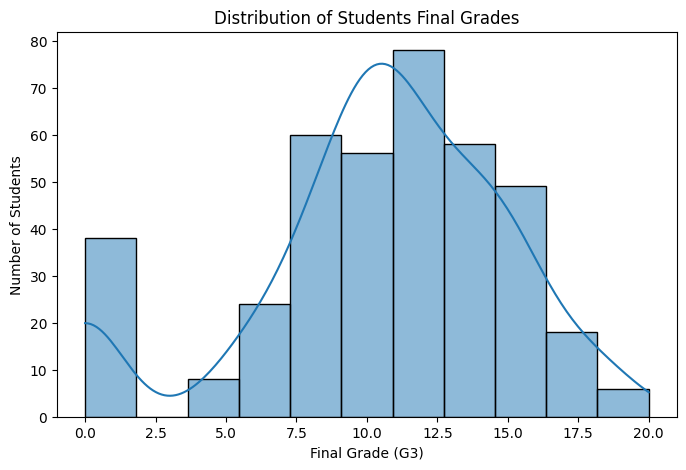

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'G3' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x='G3', bins=11, kde=True)

    plt.title('Distribution of Students Final Grades')
    plt.xlabel('Final Grade (G3)')
    plt.ylabel('Number of Students')
    plt.show()

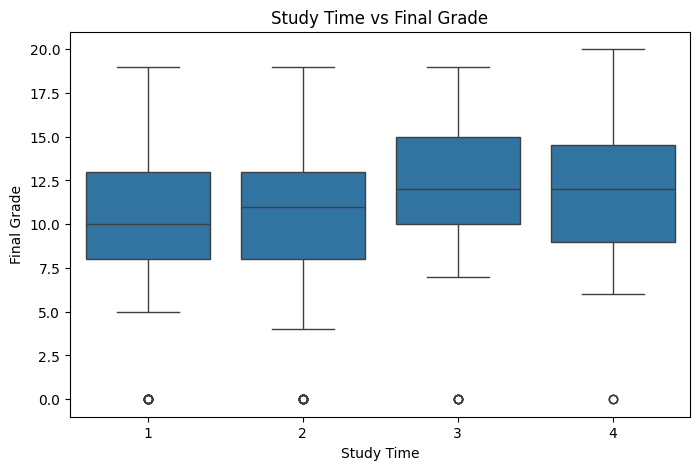

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='studytime', y='G3')

plt.title('Study Time vs Final Grade')
plt.xlabel('Study Time')
plt.ylabel('Final Grade')
plt.show()

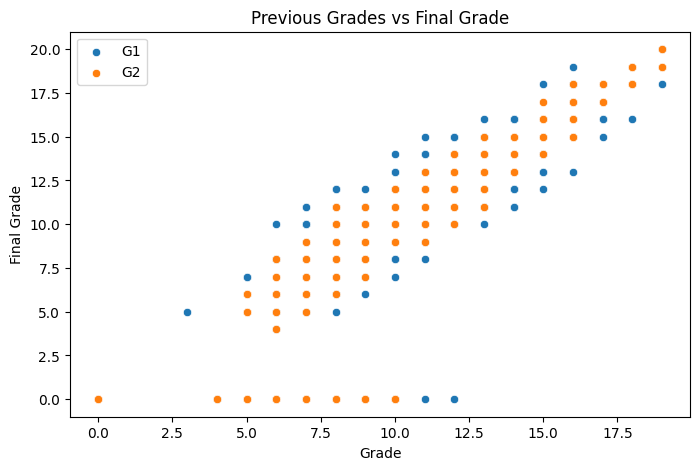

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='G1', y='G3', label='G1')
sns.scatterplot(data=df, x='G2', y='G3', label='G2')

plt.title('Previous Grades vs Final Grade')
plt.xlabel('Grade')
plt.ylabel('Final Grade')
plt.legend()
plt.show()

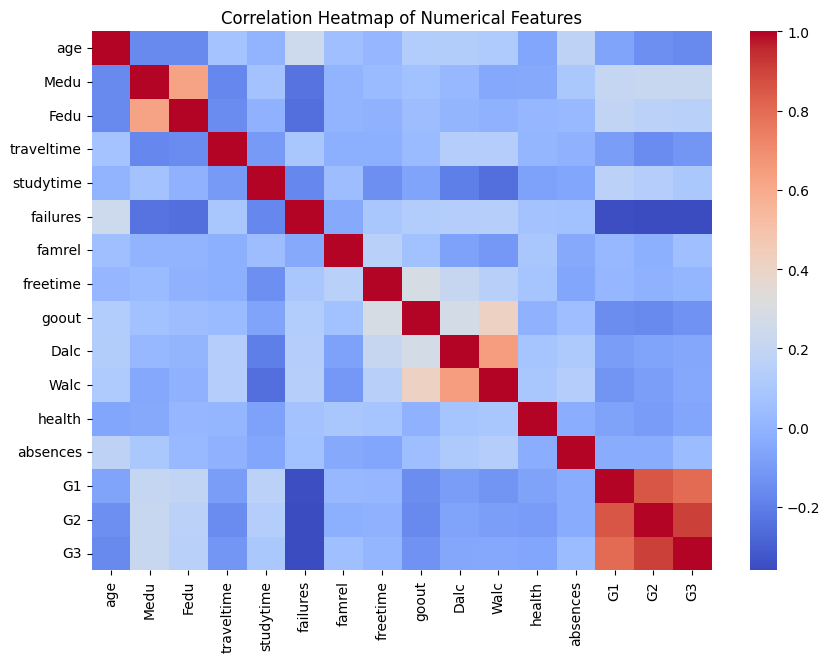

In [ ]:
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include='number')
sns.heatmap(
    numeric_df.corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [ ]:
# Create target variable
df['Result'] = (df['G3'] >= 10).astype(int)

# 1 = Pass, 0 = Fail
print("Class distribution:")
print(df['Result'].value_counts())

print("\nClass percentages:")
print((df['Result'].value_counts(normalize=True) * 100).round(2))

Class distribution:
Result
1    265
0    130
Name: count, dtype: int64

Class percentages:
Result
1    67.09
0    32.91
Name: proportion, dtype: float64


In [ ]:
# Separate input features and target
X = df.drop(columns=['G3', 'Result', 'G1', 'G2'])
y = df['Result']

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define preprocessing pipelines for numerical and categorical data
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC()
}

results = []
trained_models = {}

for name, model in models.items():

    # Preprocess data and train the model
    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    # Predict test-set results
    y_pred = pipeline.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy * 100, 2)
    })

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=['Fail', 'Pass'],
        zero_division=0
    ))

# Display model comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by='Accuracy (%)', ascending=False
)

display(results_df)


Model: Logistic Regression
Accuracy: 65.82 %
              precision    recall  f1-score   support

        Fail       0.47      0.35      0.40        26
        Pass       0.72      0.81      0.76        53

    accuracy                           0.66        79
   macro avg       0.60      0.58      0.58        79
weighted avg       0.64      0.66      0.64        79


Model: Decision Tree
Accuracy: 65.82 %
              precision    recall  f1-score   support

        Fail       0.48      0.50      0.49        26
        Pass       0.75      0.74      0.74        53

    accuracy                           0.66        79
   macro avg       0.62      0.62      0.62        79
weighted avg       0.66      0.66      0.66        79


Model: KNN
Accuracy: 60.76 %
              precision    recall  f1-score   support

        Fail       0.31      0.15      0.21        26
        Pass       0.67      0.83      0.74        53

    accuracy                           0.61        79
   macro avg

,Model,Accuracy (%)
3,SVM,68.35
0,Logistic Regression,65.82
1,Decision Tree,65.82
2,KNN,60.76


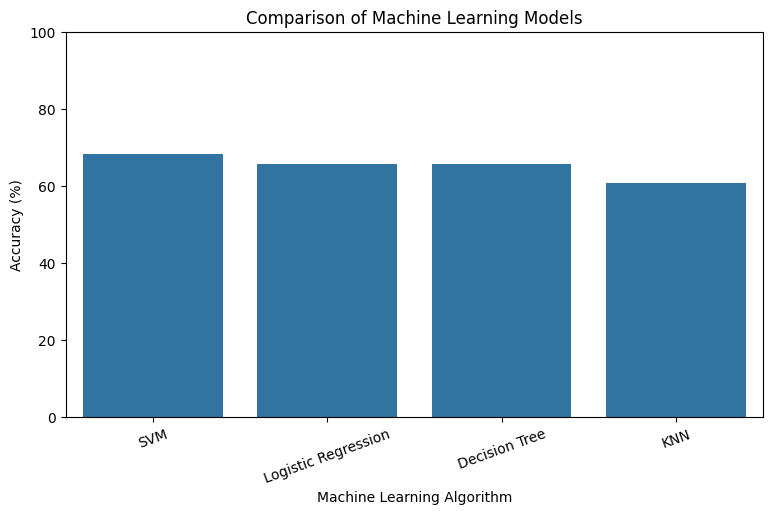

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy (%)'
)

plt.title('Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Algorithm')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.show()

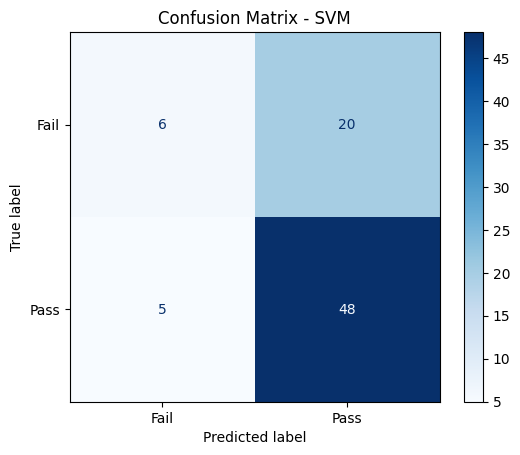

Best model: SVM
Confusion matrix:
[[ 6 20]
 [ 5 48]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Select the model with the highest accuracy
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

# Make predictions
y_pred_best = best_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail', 'Pass']
)

display.plot(cmap='Blues')
plt.title('Confusion Matrix - ' + best_model_name)
plt.show()

print("Best model:", best_model_name)
print("Confusion matrix:")
print(cm)

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report - SVM")
print(classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=['Fail', 'Pass'],
    zero_division=0
))

Classification Report - SVM
              precision    recall  f1-score   support

        Fail       0.55      0.23      0.32        26
        Pass       0.71      0.91      0.79        53

    accuracy                           0.68        79
   macro avg       0.63      0.57      0.56        79
weighted avg       0.65      0.68      0.64        79



In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display

comparison = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    comparison.append({
        'Model': name,
        'Accuracy (%)': round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        'Fail Precision': round(
            precision_score(y_test, predictions, pos_label=0,
                            zero_division=0), 2
        ),
        'Fail Recall': round(
            recall_score(y_test, predictions, pos_label=0,
                         zero_division=0), 2
        ),
        'Fail F1-score': round(
            f1_score(y_test, predictions, pos_label=0,
                     zero_division=0), 2
        )
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.sort_values(
    by='Fail Recall', ascending=False
))

,Model,Accuracy (%),Fail Precision,Fail Recall,Fail F1-score
1,Decision Tree,65.82,0.48,0.50,0.49
0,Logistic Regression,65.82,0.47,0.35,0.40
3,SVM,68.35,0.55,0.23,0.32
2,KNN,60.76,0.31,0.15,0.21
